# Premier League Simulation — Performance Analysis
Task D: baseline comparison, parallel execution times, and speedup.

Note: these are preliminary results. The baseline and parallel runs use different season counts, so direct speedup is not yet valid.

In [1]:
import csv
import matplotlib.pyplot as plt
from pathlib import Path

root = Path('..')
baseline_path = root / 'results/array/baseline-100k/timing.csv'
parallel_path = root / 'results/array/job-30256/timing_all_tasks.csv'

with baseline_path.open() as f:
    baseline = next(csv.DictReader(f))
with parallel_path.open() as f:
    tasks = list(csv.DictReader(f))

print('Baseline seasons:', baseline['seasons'])
print('Parallel seasons per task:', [r['seasons'] for r in tasks])
print('Baseline simulation time:', baseline['simulation_seconds'])
print('Parallel task times:', [r['simulation_seconds'] for r in tasks])

Baseline seasons: 100000
Parallel seasons per task: ['25000', '25000', '25000', '25000']
Baseline simulation time: 6.767281593289226
Parallel task times: ['1.53570598596707', '1.5393382390029728', '1.532631245907396', '1.6842268067412078']


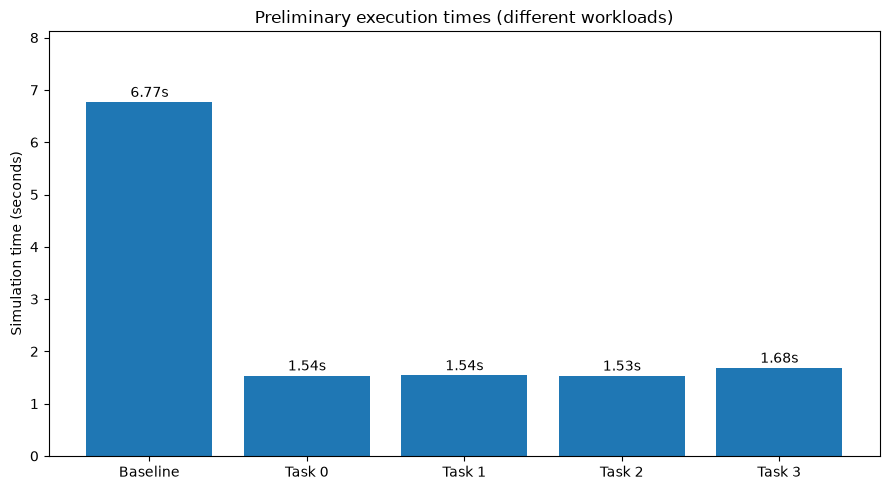

In [2]:
labels = ['Baseline'] + [f'Task {r["task_id"]}' for r in tasks]
times = [float(baseline['simulation_seconds'])] + [float(r['simulation_seconds']) for r in tasks]

plt.figure(figsize=(9, 5))
bars = plt.bar(labels, times)
plt.ylabel('Simulation time (seconds)')
plt.title('Preliminary execution times (different workloads)')
for bar, value in zip(bars, times):
    plt.text(bar.get_x() + bar.get_width()/2, value + 0.1, f'{value:.2f}s', ha='center')
plt.ylim(0, max(times)*1.2)
plt.tight_layout()
plt.show()

In [3]:
%pip install matplotlib


[notice] A new release of pip is available: 23.1.2 -> 26.3
[notice] To update, run: /home/pc48/plot-env/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install --user matplotlib

ERROR: Can not perform a '--user' install. User site-packages are not visible in this virtualenv.

[notice] A new release of pip is available: 23.1.2 -> 26.3
[notice] To update, run: /home/pc48/plot-env/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
import csv
from pathlib import Path

root = Path("..")

with open(root / "results/baseline-100k-test/timing.csv") as f:
    baseline = next(csv.DictReader(f))

with open(root / "results/array-100k-test/timing_all_tasks.csv") as f:
    tasks = list(csv.DictReader(f))

sequential_time = float(baseline["simulation_seconds"])
parallel_time = max(float(task["simulation_seconds"]) for task in tasks)

speedup = sequential_time / parallel_time
ideal_speedup = 4
efficiency = speedup / ideal_speedup

print(f"Sequential simulation time: {sequential_time:.2f} s")
print(f"Parallel maximum task time: {parallel_time:.2f} s")
print(f"Preliminary speedup: {speedup:.2f}x")
print(f"Ideal speedup for 4 workers: {ideal_speedup:.2f}x")
print(f"Conditional efficiency (4 workers): {efficiency:.1%}")

Sequential simulation time: 7.41 s
Parallel maximum task time: 5.02 s
Preliminary speedup: 1.48x
Ideal speedup for 4 workers: 4.00x
Conditional efficiency (4 workers): 36.9%


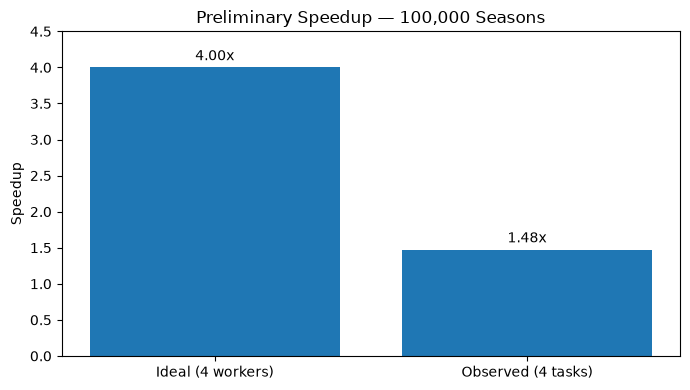

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.bar(["Ideal (4 workers)", "Observed (4 tasks)"],
        [4, speedup])

plt.ylabel("Speedup")
plt.title("Preliminary Speedup — 100,000 Seasons")
plt.ylim(0, 4.5)

for i, value in enumerate([4, speedup]):
    plt.text(i, value + 0.1, f"{value:.2f}x", ha="center")

plt.tight_layout()
plt.show()

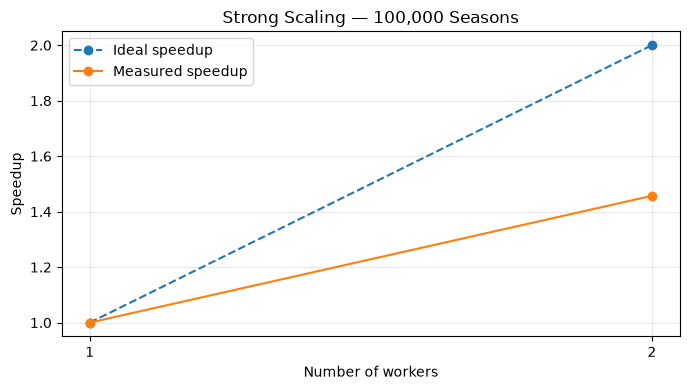

1 worker(s): 7.42s | Speedup: 1.00x | Efficiency: 100.0%
2 worker(s): 5.09s | Speedup: 1.46x | Efficiency: 72.9%


In [7]:
import csv
import matplotlib.pyplot as plt
from pathlib import Path

root = Path("..")
workers = [1, 2]
times = []

for w in workers:
    with open(root / f"results/scaling-pool-{w}w/timing.csv") as f:
        row = next(csv.DictReader(f))
        times.append(float(row["simulation_seconds"]))

speedups = [times[0] / t for t in times]
efficiencies = [100 * s / w for s, w in zip(speedups, workers)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(workers, workers, "o--", label="Ideal speedup")
ax.plot(workers, speedups, "o-", label="Measured speedup")
ax.set_xticks(workers)
ax.set_xlabel("Number of workers")
ax.set_ylabel("Speedup")
ax.set_title("Strong Scaling — 100,000 Seasons")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for w, t, s, e in zip(workers, times, speedups, efficiencies):
    print(f"{w} worker(s): {t:.2f}s | Speedup: {s:.2f}x | Efficiency: {e:.1f}%")

# Strong Scaling Results and Interpretation

We tested the Premier League simulation by running it 100,000 times and saw how it worked with one or two workers doing the job at the same time.

The single-worker version took 7.42 seconds to finish, but the 2-worker version was faster, completing in just 5.09 seconds. This means it was 1.46 times quicker. It also had a parallel efficiency of 72.9%.

The two versions gave the same results as the standard one done step by step, which showed they were correct.

The speedup we saw was not as high as it could be, which is twice as fast. This is probably because managing processes and coordinating tasks takes some time, and some parts of the simulation still have to run one after the other.

We tried using 4 workers, but the system would only let us use 2 CPUs for each task. So, we can't give a good measurement for 4 workers from this test.

These results are based on initial tests in our current setup. To get a better sense of how things work on a larger scale, we would need to do more experiments in a controlled environment and take more measurements. This would give us a more complete picture.

In [10]:
import pandas as pd

df = pd.read_csv("../results/strong_pool/job-30371/scaling.csv")

print("Total measurements:", len(df))
print("Worker counts:", sorted(df["workers"].unique()))
print("Repetitions per worker:")
print(df.groupby("workers").size())

Total measurements: 30
Worker counts: [np.int64(1), np.int64(2), np.int64(4), np.int64(8), np.int64(16), np.int64(32)]
Repetitions per worker:
workers
1     5
2     5
4     5
8     5
16    5
32    5
dtype: int64


In [9]:
summary = df.groupby("workers")["time"].agg(
    median="median",
    minimum="min",
    maximum="max"
).sort_index()

baseline_time = summary.loc[1, "median"]

summary["speedup"] = baseline_time / summary["median"]
summary["efficiency_pct"] = 100 * summary["speedup"] / summary.index

summary["serial_fraction"] = (
    (1 / summary["speedup"]) - (1 / summary.index)
) / (1 - 1 / summary.index)

summary.loc[1, "serial_fraction"] = float("nan")

print(summary.round(3).to_string())

          median  minimum  maximum  speedup  efficiency_pct  serial_fraction
workers                                                                     
1        122.611  122.489  123.648    1.000         100.000              NaN
2         61.862   61.698   62.197    1.982          99.100            0.009
4         31.184   31.029   31.511    3.932          98.296            0.006
8         15.877   15.714   16.033    7.722          96.531            0.005
16         8.782    8.556    8.875   13.961          87.257            0.010
32         5.019    4.849    5.336   24.429          76.341            0.010


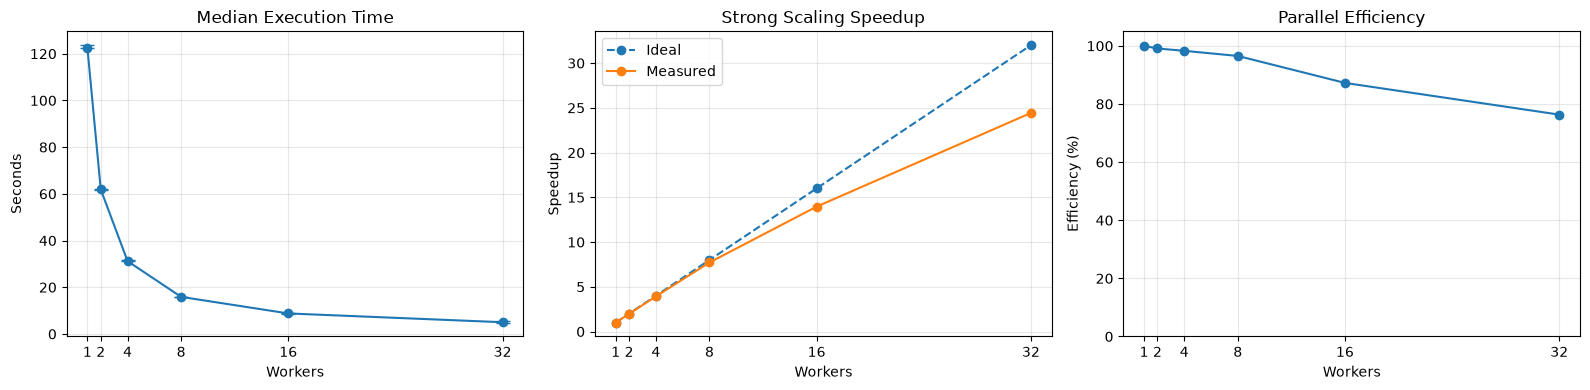

In [11]:
import matplotlib.pyplot as plt

workers = summary.index.to_numpy()
medians = summary["median"].to_numpy()
mins = summary["minimum"].to_numpy()
maxs = summary["maximum"].to_numpy()
speedups = summary["speedup"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].errorbar(
    workers, medians,
    yerr=[medians - mins, maxs - medians],
    fmt="o-", capsize=5
)
axes[0].set_title("Median Execution Time")
axes[0].set_xlabel("Workers")
axes[0].set_ylabel("Seconds")

axes[1].plot(workers, workers, "o--", label="Ideal")
axes[1].plot(workers, speedups, "o-", label="Measured")
axes[1].set_title("Strong Scaling Speedup")
axes[1].set_xlabel("Workers")
axes[1].set_ylabel("Speedup")
axes[1].legend()

axes[2].plot(workers, summary["efficiency_pct"], "o-")
axes[2].set_title("Parallel Efficiency")
axes[2].set_xlabel("Workers")
axes[2].set_ylabel("Efficiency (%)")
axes[2].set_ylim(0, 105)

for ax in axes:
    ax.set_xticks(workers)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Cluster Scaling and Profiling Analysis

We took a close look at 30 measurements from a Slurm job, specifically number 30371. This job used simulations to play out 2 million Premier League seasons. We tried out different setups with 1, 2, 4, 8, 16, and 32 workers, and we did each setup five times to see what would happen.

We saw a big drop in how long things took to run - from 122.61 seconds with just one worker to 5.02 seconds with 32 workers. This meant we got a speedup of 24.43 times and were able to use our workers pretty efficiently, at a rate of 76.3%.

Things worked really well when we had a small team, but as we added more people, it got less efficient. It seems that when you have a lot of workers, the extra work of managing them and other tasks that can't be done at the same time starts to slow everything down.

We used Amdahl's law to figure out the serial fraction, and it looks like it's around 0.5% to 1.0% for the different setups we tested.

We took a closer look at what happened with Slurm job 30261. It turned out that a lot of time was spent running `simulate_batch` - almost 20 seconds out of a total of 20.53 seconds. Other functions like `update_table` and `generate_batch` also took up a big chunk of that time. The numbers showed that `simulate_batch` used 19.92 seconds, which is a big part of the whole process.

This backs up what we've seen - the simulation can be broken down into lots of smaller tasks that can be done at the same time. But profiling doesn't give us a direct reading of how much of the workload is serial, so we should look at these two findings as supporting each other, rather than expecting them to be identical.

The simulation works really well with up to 32 workers, but it starts to slow down when you add more workers than that.